In [33]:
import iris
import warnings

from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import numpy as np
import sys
import subprocess
import matplotlib.pyplot as plt
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole
from pathlib import Path
sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes")

import momentum_flux_funcs as tx

help(tx.plot_flux)

Help on function plot_flux in module momentum_flux_funcs:

plot_flux(plot_title_affix, cubelist_s_path, cubelist_m_path, cubelist_mo_path, orog_cube_path, save_plot=True)



In [44]:
path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/"

raw_flux_dir = f"{path_base}/iop_17_18/iop_17_18_raw_sonde_flux_arrays"
model_flux_dir = f"{path_base}/iop_17_18/iop_17_18_model_sonde_flux_arrays"
coarse_flux_dir = f"{path_base}/iop_17_18/iop_17_18_coarse_sonde_flux_arrays"

model_sonde_list = sorted((Path(model_flux_dir)).glob("*.npz"))
raw_sonde_list = sorted(Path(raw_flux_dir).glob("*.npz"))
coarse_sonde_list = sorted(Path(coarse_flux_dir).glob("*.npz"))

index = 1

raw_flux_path = raw_sonde_list[index]
model_flux_path = model_sonde_list[index]
coarse_flux_path = coarse_sonde_list[index]

sonde_id = raw_sonde_list[index].stem[13:21]

sonde_id



'S0240175'

In [45]:
# flux from raw sonde
Flux_u_r = np.load(f"{raw_flux_path}")["Flux_u"]
Flux_v_r = np.load(f"{raw_flux_path}")["Flux_v"]
alts_km = np.load(f"{raw_flux_path}")["alt_s_km"]

# flux from model coarsened sonde
Flux_u_s = np.load(f"{coarse_flux_path}")["Flux_u"]
Flux_v_s = np.load(f"{coarse_flux_path}")["Flux_v"]

# flux from model sonde
Flux_u_m = np.load(f"{model_flux_path}")["Flux_u"]
Flux_v_m = np.load(f"{model_flux_path}")["Flux_v"]


In [46]:
# Cross heights
model_data_dir = f"{path_base}/iop_17_18/iop_17_18_model_sonde_data"
coarse_data_dir = f"{path_base}/iop_17_18/iop_17_18_coarse_sonde_data"

model_data_list = sorted((Path(model_data_dir)).glob("*.nc"))
coarse_data_list = sorted(Path(coarse_data_dir).glob("*.nc"))

index = 0

model_data_path = model_data_list[index]
coarse_data_path = coarse_data_list[index]

orog_data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/raso_through_model_output/"
# Output file where the orography lives
data_path_orog = f"{orog_data_path_base}/orography_u-eb392_run1_0p3km.nc"

original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

cross_heights = tx.vert_levels_for_sonde(sonde_data_path=coarse_data_path, 
                                        model_sonde_data_path=model_data_path, 
                                        model_data_path=original_model_data_path, 
                                        model_orog_path=data_path_orog)

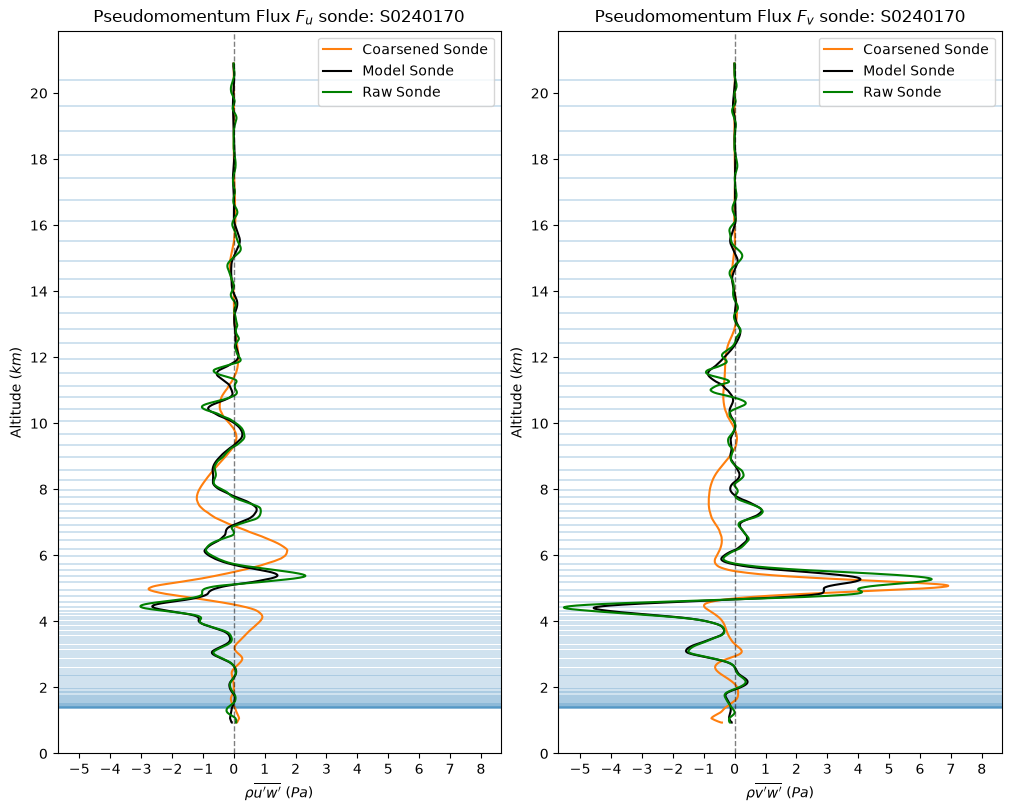

In [38]:
plot_title_affix = sonde_id

# Plot the Fluxes
fig = plt.figure(figsize=(10,8), layout="constrained") 
ax = fig.subplots(1,2).flatten()

ylim = (0,None)

max_flux = np.max(np.array([np.max(Flux_u_s), np.max(Flux_u_m), np.max(Flux_v_s), np.max(Flux_v_m)]))
min_flux = np.min(np.array([np.min(Flux_u_s), np.min(Flux_u_m), np.min(Flux_v_s), np.min(Flux_v_m)]))

xlim = (1.25*min_flux, 1.25*max_flux)

# Plot zonal flux
ax[0].plot(Flux_u_s, alts_km, color="C1", label="Coarsened Sonde")
ax[0].plot(Flux_u_m, alts_km, color="k", label="Model Sonde")
ax[0].plot(Flux_u_r, alts_km, color="green", label="Raw Sonde")
ax[0].axvline(0, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[0].set_xlim(xlim)
ax[0].locator_params(axis="x", nbins=15)
ax[0].set_xlabel(r"$\rho \overline{u^\prime w^\prime}$ ($Pa$)")

ax[0].set_ylim(ylim)
ax[0].locator_params(axis="y", nbins=15)
ax[0].set_ylabel(r"Altitude ($km$)")

ax[0].set_title(rf"Pseudomomentum Flux $F_u$ sonde: {plot_title_affix}")

#Plot meridional flux
ax[1].plot(Flux_v_s, alts_km, color="C1", label="Coarsened Sonde")
ax[1].plot(Flux_v_m, alts_km, color="k", label="Model Sonde")
ax[1].plot(Flux_v_r, alts_km, color="green", label="Raw Sonde")
ax[1].axvline(0, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[1].set_xlim(xlim)
ax[1].locator_params(axis="x", nbins=15)
ax[1].set_xlabel(r"$\rho \overline{v^\prime w^\prime}$ ($Pa$)")

ax[1].set_ylim(ylim)
ax[1].locator_params(axis="y", nbins=15)
ax[1].set_ylabel(r"Altitude ($km$)")

ax[1].set_title(rf"Pseudomomentum Flux $F_v$ sonde: {plot_title_affix}")

ax[0].legend()
ax[1].legend()

for height in cross_heights:
    if np.isfinite(height):
        ax[0].axhline(height*1e-3, linewidth=0.3, alpha=1, zorder=1)
        ax[1].axhline(height*1e-3, linewidth=0.3, alpha=1, zorder=1)

# if save_plot == True:
#     plt.savefig(f"Momentum_flux_sonde_id_{plot_title_affix}.png")
# else: 
#     plt.close()

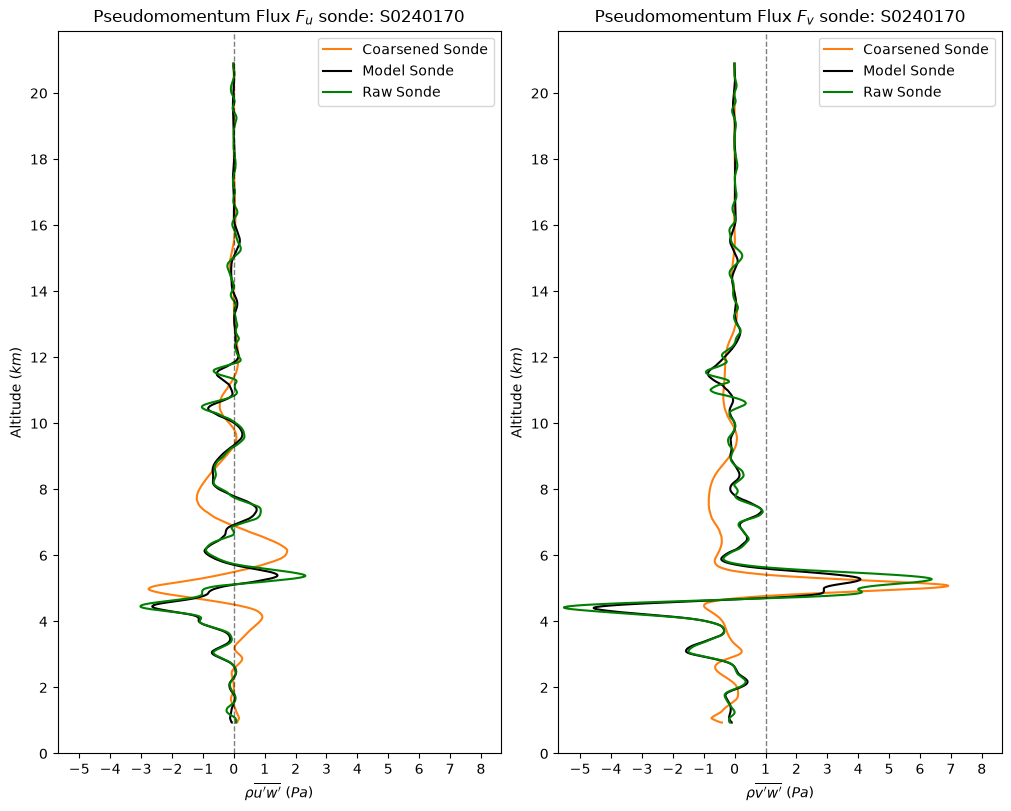

In [39]:
# Difference plot between raw sonde and model
plot_title_affix = sonde_id

# Plot the Fluxes
fig = plt.figure(figsize=(10,8), layout="constrained") 
ax = fig.subplots(1,2).flatten()

ylim = (0,None)

diff_u = "" 

max_flux = np.max(np.array([np.max(Flux_u_s), np.max(Flux_u_m), np.max(Flux_v_s), np.max(Flux_v_m)]))
min_flux = np.min(np.array([np.min(Flux_u_s), np.min(Flux_u_m), np.min(Flux_v_s), np.min(Flux_v_m)]))

xlim = (1.25*min_flux, 1.25*max_flux)

# Plot zonal flux
ax[0].plot(Flux_u_s, alts_km, color="C1", label="Coarsened Sonde")
ax[0].plot(Flux_u_m, alts_km, color="k", label="Model Sonde")
ax[0].plot(Flux_u_r, alts_km, color="green", label="Raw Sonde")
ax[0].axvline(0, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[0].set_xlim(xlim)
ax[0].locator_params(axis="x", nbins=15)
ax[0].set_xlabel(r"$\rho \overline{u^\prime w^\prime}$ ($Pa$)")

ax[0].set_ylim(ylim)
ax[0].locator_params(axis="y", nbins=15)
ax[0].set_ylabel(r"Altitude ($km$)")

ax[0].set_title(rf"Pseudomomentum Flux $F_u$ sonde: {plot_title_affix}")

#Plot meridional flux
ax[1].plot(Flux_v_s, alts_km, color="C1", label="Coarsened Sonde")
ax[1].plot(Flux_v_m, alts_km, color="k", label="Model Sonde")
ax[1].plot(Flux_v_r, alts_km, color="green", label="Raw Sonde")
ax[1].axvline(1, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[1].set_xlim(xlim)
ax[1].locator_params(axis="x", nbins=15)
ax[1].set_xlabel(r"$\rho \overline{v^\prime w^\prime}$ ($Pa$)")

ax[1].set_ylim(ylim)
ax[1].locator_params(axis="y", nbins=15)
ax[1].set_ylabel(r"Altitude ($km$)")

ax[1].set_title(rf"Pseudomomentum Flux $F_v$ sonde: {plot_title_affix}")

ax[0].legend()
ax[1].legend()